In [1]:
import pandas as pd
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

In [2]:
df = yf.download('AAPL',
    start='2000-01-01',
    end='2010-12-31',
    progress=False)


df

Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2000-01-03,0.837002,0.841208,0.760359,0.784193,535796800
2000-01-04,0.766435,0.827188,0.756620,0.809430,512377600
2000-01-05,0.777650,0.826721,0.770173,0.775781,778321600
2000-01-06,0.710354,0.800083,0.710354,0.793540,767972800
2000-01-07,0.744002,0.755219,0.714093,0.721570,460734400
...,...,...,...,...,...
2010-12-23,9.678757,9.725117,9.665896,9.720630,223157200
2010-12-27,9.711058,9.733790,9.616543,9.656324,249816000


In [3]:
df = pd.DataFrame(df["Close"]["AAPL"])
df.rename(columns={'AAPL':'close'}, inplace=True)
df


,close
Date,
2000-01-03,0.837002
2000-01-04,0.766435
2000-01-05,0.777650
2000-01-06,0.710354
2000-01-07,0.744002
...,...
2010-12-23,9.678757
2010-12-27,9.711058
2010-12-28,9.734691


In [4]:
df['simple_rtn'] = df["close"].pct_change()
df['log_rtn'] = np.log(df["close"]/df["close"].shift(1))
df

,close,simple_rtn,log_rtn
Date,,,
2000-01-03,0.837002,NaN,NaN
2000-01-04,0.766435,-0.084310,-0.088077
2000-01-05,0.777650,0.014633,0.014527
2000-01-06,0.710354,-0.086538,-0.090514
2000-01-07,0.744002,0.047369,0.046281
...,...,...,...
2010-12-23,9.678757,-0.004797,-0.004809
2010-12-27,9.711058,0.003337,0.003332
2010-12-28,9.734691,0.002434,0.002431


[Text(0.5, 0, 'Date'), Text(0, 0.5, 'Log returns (%)')]

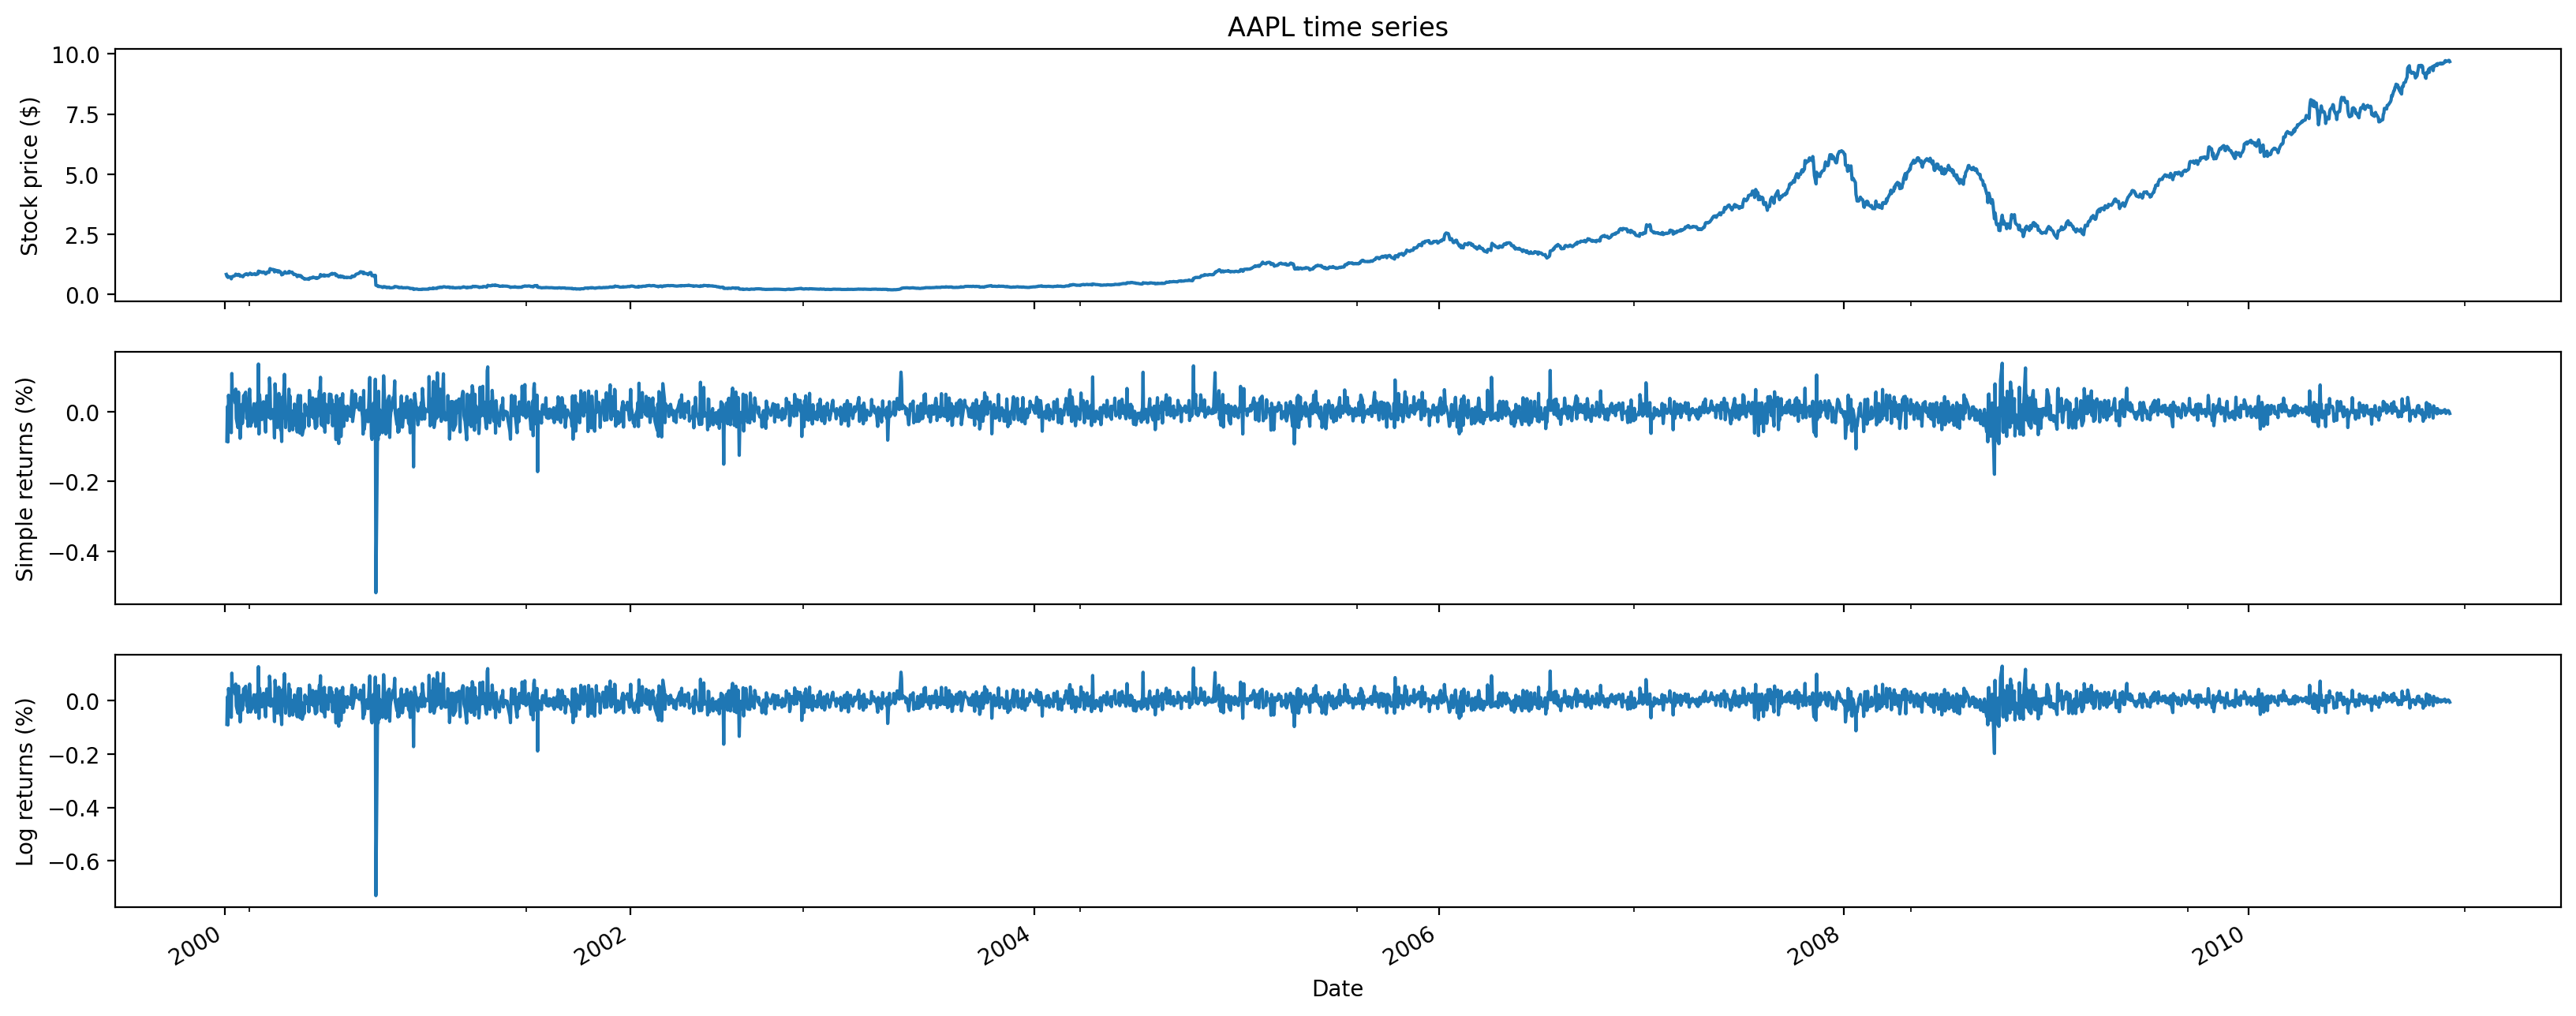

In [5]:
fig, ax = plt.subplots(3, 1, figsize=(20, 8), sharex=True)
df.close.plot(ax=ax[0])
ax[0].set(title = 'AAPL time series', ylabel = 'Stock price ($)')
df.simple_rtn.plot(ax=ax[1])
ax[1].set(ylabel = 'Simple returns (%)')
df.log_rtn.plot(ax=ax[2])
ax[2].set(xlabel = 'Date', ylabel = 'Log returns (%)')

# plotly

In [50]:
from plotly.subplots import make_subplots
import plotly.graph_objects as go

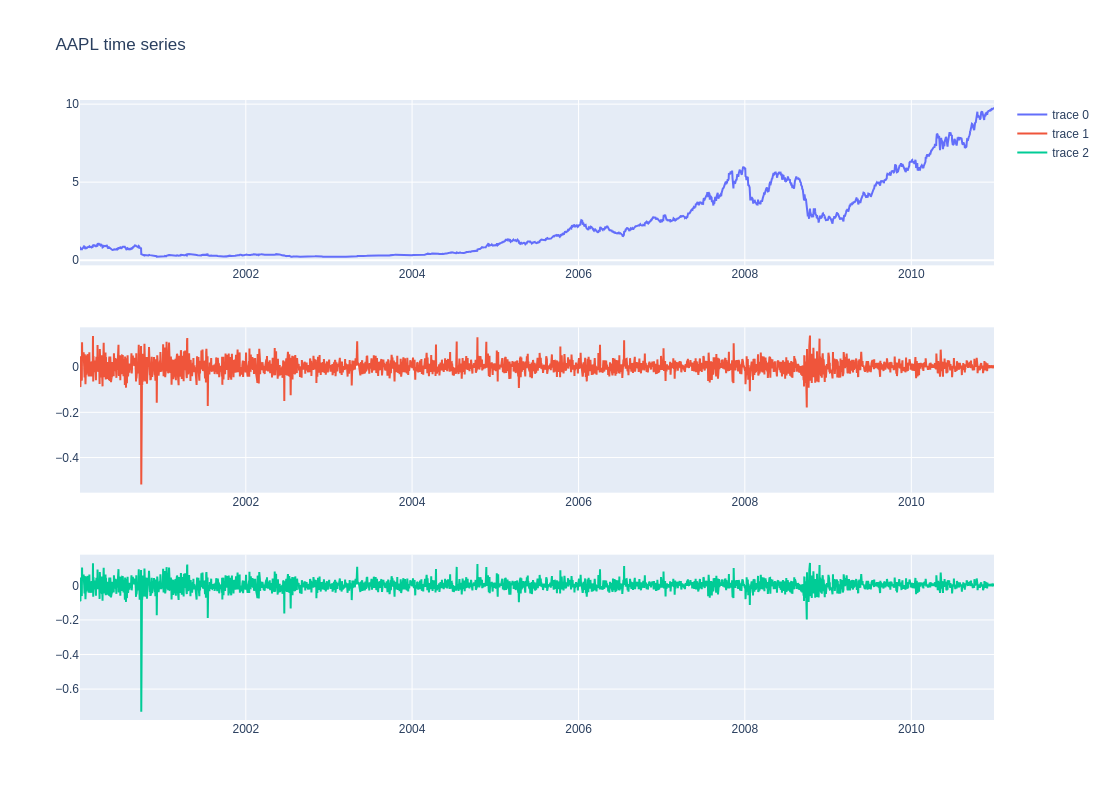

In [53]:
df.dropna(axis=0, inplace=True)
df = df.astype(float)


fig = make_subplots(rows=3, cols=1)

for i in range(0,len(df.columns)):
    fig.add_trace(go.Scatter(
    x=df.index,
    y=df[df.columns[i]],
        ), row=i+1, col=1)



fig.update_layout(height=800, width=1000, title_text='AAPL time series')
fig.show()

In [38]:
df.columns

Index(['close', 'simple_rtn', 'log_rtn'], dtype='object')